# Week 1: GCN+MLP baseline vs GCN+QNN on DrugBank DDI (core experiment)

**Deliverables covered:** data pipeline, fixed folds (random + cold-start S1/S2), classical baseline (GCN+MLP), first quantum model (GCN encoder + QNN decoder).

**How to run:** `Runtime > Run all` in Colab. Needs internet once (DrugBank download via PyTDC). Edit only the **Config** cell.

**Design (identical for both models, so the comparison is controlled)**
- Binary link prediction on unordered pairs. Positives = DrugBank pairs; negatives = uniform unobserved pairs, 1:1.
- Features: 2048-bit Morgan fingerprints → PCA(d) fit on *training drugs only* → standardised.
- Encoder: 2-layer GCN over the drug graph (training positives only). Pair → `[hi+hj, hi*hj]` → Linear → d values → **decoder**.
- Decoder: **MLP** (classical baseline) vs **QNN** (d qubits, angle encoding, RY/RZ + CNOT ring, ⟨Z⟩ readout). Same seed gives the same encoder init and the same batches for both.
- The QNN is simulated as an exact statevector in PyTorch and cross-checked against Qiskit (section 5).

## 0. Setup

In [ ]:
# Colab / fresh environment. Safe to re-run; skip if everything is already installed.
# NOTE: do not `pip install PyTDC` normally. It pins an old scikit-learn that has no wheel for new Python versions,
# so pip tries to compile it from source and fails. Install PyTDC with --no-deps and add only what it really needs.
%pip install -q rdkit qiskit
%pip install -q --no-deps PyTDC
%pip install -q tqdm fuzzywuzzy huggingface_hub tiledbsoma cellxgene-census gget "setuptools<81"
# (torch, scikit-learn, pandas, scipy, matplotlib are already in Colab; locally: pip install torch scikit-learn pandas scipy matplotlib)

## 1. Config  (the only cell you need to edit)

In [ ]:
DATA_SOURCE = "tdc"        # "tdc"  -> download DrugBank DDI via PyTDC (the real dataset)
                           # "csv"  -> use CSV_PATH (a TDC-format export)
                           # "synthetic" -> pipeline smoke test ONLY, results are meaningless
CSV_PATH    = "drugbank_ddi.csv"

N_TOTAL  = 20000           # fixed labeled-pair subsample used by ALL models (0 = all pairs; quantum then gets slow)
D_LIST   = [8]             # PCA dims = number of qubits. Use [8, 12] for the full study.
SEEDS    = [0, 1, 2, 3, 4]  # 5 seeds, as in the proposal (about 4 min per seed on a CPU)
EPOCHS   = 200
Q_LAYERS = 2               # variational layers in the QNN
Q_LR     = 0.05            # learning rate for QNN circuit parameters (classical parts use LR below)
LR       = 1e-2
OUT_DIR  = "results"
ART_DIR  = "artifacts"

## 2. Imports and data loading

In [ ]:
import os, time, math, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
RDLogger.DisableLog("rdApp.*"); warnings.filterwarnings("ignore")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("torch", torch.__version__, "| cpus", os.cpu_count())


def make_synthetic(n_drugs=400):
    # SYNTHETIC stand-in for smoke-testing the code. NOT DrugBank. Results on it mean nothing.
    rng = np.random.default_rng(0)
    frag = ["C","CC","C(=O)","N","O","c1ccccc1","C(F)","C(Cl)","S","C#N","C(=O)O","N(C)C","C1CC1","c1ccncc1"]
    smiles, seen = [], set()
    while len(smiles) < n_drugs:
        m = Chem.MolFromSmiles("".join(rng.choice(frag, size=rng.integers(3, 9))))
        if m is not None:
            s = Chem.MolToSmiles(m)
            if s not in seen: seen.add(s); smiles.append(s)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = np.stack([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles]).astype(np.float32)
    z = fp @ rng.normal(size=(2048, 4)); z = (z - z.mean(0)) / (z.std(0) + 1e-6)
    score = z @ z.T + 0.5 * rng.normal(size=(n_drugs, n_drugs))
    iu = np.triu_indices(n_drugs, 1); sel = score[iu] > np.quantile(score[iu], 0.93)
    rows = [(f"SYN{a:04d}", smiles[a], f"SYN{b:04d}", smiles[b]) for a, b in zip(iu[0][sel], iu[1][sel])]
    return pd.DataFrame(rows, columns=["Drug1_ID", "Drug1", "Drug2_ID", "Drug2"])


def load_ddi_table():
    if DATA_SOURCE == "synthetic":
        print("!" * 70, "\nSYNTHETIC DATA: pipeline smoke test only, NOT DrugBank, NOT results\n" + "!" * 70)
        df = make_synthetic()
    elif DATA_SOURCE == "csv":
        df = pd.read_csv(CSV_PATH)
    else:
        from tdc.multi_pred import DDI
        df = DDI(name="DrugBank").get_data()
        df.to_csv("drugbank_ddi.csv", index=False)      # cache a local copy (do NOT commit this file: DrugBank licence)
    need = ["Drug1_ID", "Drug1", "Drug2_ID", "Drug2"]
    missing = [c for c in need if c not in df.columns]
    assert not missing, f"missing columns {missing}; got {list(df.columns)}"
    return df[need].copy()


df = load_ddi_table()
print("rows in table:", len(df)); df.head(3)

torch 2.14.1+cpu | cpus 2


Downloading...
100%|██████████| 44.4M/44.4M [00:03<00:00, 12.0MiB/s]
Loading...
Done!


rows in table: 191808


,Drug1_ID,Drug1,Drug2_ID,Drug2
0,DB04571,CC1=CC2=CC3=C(OC(=O)C=C3C)C(C)=C2O1,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...
1,DB00855,NCC(=O)CCC(O)=O,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...
2,DB09536,O=[Ti]=O,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...


## 3. Data pipeline: drugs, positives, negatives, folds, features
Pairs are treated as unordered (`i < j`). Cold-start: 20% of drugs are held out as "new"; train/val use old-old pairs only;
**S1** = exactly one new drug, **S2** = both new.

In [ ]:
def build_drugs_and_positives(df):
    smi = {}
    for a, s in zip(df.Drug1_ID, df.Drug1): smi.setdefault(a, s)
    for a, s in zip(df.Drug2_ID, df.Drug2): smi.setdefault(a, s)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    ids, fps = [], []
    for k, s in smi.items():
        m = Chem.MolFromSmiles(s) if isinstance(s, str) else None
        if m is None: continue                       # drop drugs RDKit cannot parse
        ids.append(k); fps.append(gen.GetFingerprintAsNumPy(m).astype(np.uint8))
    index = {k: i for i, k in enumerate(ids)}
    pairs = set()
    for a, b in zip(df.Drug1_ID, df.Drug2_ID):
        if a in index and b in index and a != b:
            i, j = index[a], index[b]; pairs.add((min(i, j), max(i, j)))
    return ids, np.stack(fps), np.array(sorted(pairs), dtype=np.int64)


def sample_negatives(pos, n_drugs, n_neg, rng):
    known = set((pos[:, 0] * n_drugs + pos[:, 1]).tolist()); out = set()
    while len(out) < n_neg:
        i = rng.integers(0, n_drugs, size=2 * (n_neg - len(out)) + 16); j = rng.integers(0, n_drugs, size=i.shape)
        for a, b in zip(i.tolist(), j.tolist()):
            if a == b: continue
            a, b = (a, b) if a < b else (b, a); key = a * n_drugs + b
            if key in known or key in out: continue
            out.add(key)
            if len(out) == n_neg: break
    out = np.array(sorted(out), dtype=np.int64)
    return np.stack([out // n_drugs, out % n_drugs], 1)


def build_labeled_pairs(pos, n_drugs, rng, n_total=None):
    if n_total:
        pos_used = pos[np.sort(rng.choice(len(pos), size=n_total // 2, replace=False))]
    else:
        pos_used = pos
    neg = sample_negatives(pos, n_drugs, len(pos_used), rng)       # drawn against ALL known positives
    pairs = np.concatenate([pos_used, neg])
    y = np.concatenate([np.ones(len(pos_used)), np.zeros(len(neg))]).astype(np.float32)
    perm = rng.permutation(len(pairs))
    return pairs[perm], y[perm]


def random_split(n_pairs, rng, frac=(0.8, 0.1, 0.1)):
    perm = rng.permutation(n_pairs); a, b = int(frac[0] * n_pairs), int((frac[0] + frac[1]) * n_pairs)
    return {"train": perm[:a], "val": perm[a:b], "test": perm[b:]}


def cold_start_split(pairs, n_drugs, rng, new_frac=0.2, val_frac=0.1):
    new = np.zeros(n_drugs, bool); new[rng.choice(n_drugs, size=int(new_frac * n_drugs), replace=False)] = True
    n_new = new[pairs[:, 0]].astype(int) + new[pairs[:, 1]].astype(int)
    old_old = rng.permutation(np.where(n_new == 0)[0]); nv = int(val_frac * len(old_old))
    return {"train": old_old[nv:], "val": old_old[:nv],
            "test_s1": np.where(n_new == 1)[0], "test_s2": np.where(n_new == 2)[0]}, new


def check_split(pairs, y, split, n_drugs, new=None):
    all_idx = np.concatenate([split[k] for k in split])
    assert len(all_idx) == len(set(all_idx.tolist())), "a pair appears in more than one split"
    keys = pairs[:, 0] * n_drugs + pairs[:, 1]
    assert len(set(keys.tolist())) == len(keys), "duplicate pairs (a positive is also a negative?)"
    if new is not None:
        for k in ("train", "val"):
            p = pairs[split[k]]; assert not (new[p[:, 0]] | new[p[:, 1]]).any(), f"new drug leaked into {k}"
        p1, p2 = pairs[split["test_s1"]], pairs[split["test_s2"]]
        assert ((new[p1[:, 0]].astype(int) + new[p1[:, 1]].astype(int)) == 1).all()
        assert new[p2[:, 0]].all() and new[p2[:, 1]].all()


def pca_features(fps, train_pairs, d, seed=0):
    # PCA fit ONLY on drugs seen in training pairs, then standardise (train drugs only)
    tr = np.unique(train_pairs.ravel())
    pca = PCA(n_components=d, random_state=seed).fit(fps[tr].astype(np.float32))
    z = pca.transform(fps.astype(np.float32)); sc = StandardScaler().fit(z[tr])
    return sc.transform(z).astype(np.float32), float(pca.explained_variance_ratio_.sum())


def pair_vectors(x, pairs):
    a, b = x[pairs[:, 0]], x[pairs[:, 1]]
    return np.concatenate([a + b, a * b], axis=1)          # symmetric: drug order does not matter


ids, fps, pos = build_drugs_and_positives(df)
n = len(ids)
print(f"drugs = {n} | unique unordered positive pairs = {len(pos)} | density = {len(pos) / (n * (n - 1) / 2):.3f}")

drugs = 1705 | unique unordered positive pairs = 191392 | density = 0.132


## 4. Classical baseline: GCN + MLP
GCN encoder, `Linear -> d`, then an MLP decoder (d → 16 → 1).
Each epoch a random 70% of training positives form the message-passing graph and the other 30% (plus an equal number of training negatives) are the targets, so no supervised edge is visible to the encoder.
Evaluation graph = all training positives. Best epoch by validation AUPR; F1 threshold chosen on validation only.

In [ ]:
def best_f1_threshold(y, s):
    ts = np.unique(np.quantile(s, np.linspace(0.01, 0.99, 99)))
    return float(ts[int(np.argmax([f1_score(y, s >= t, zero_division=0) for t in ts]))])

def metrics(y, s, thr):
    return {"AUROC": roc_auc_score(y, s), "AUPR": average_precision_score(y, s), "F1": f1_score(y, s >= thr, zero_division=0)}

def norm_adj(n, edges, device="cpu"):
    A = torch.zeros(n, n, device=device)
    if len(edges):
        e = torch.as_tensor(edges, device=device); A[e[:, 0], e[:, 1]] = 1.0; A[e[:, 1], e[:, 0]] = 1.0
    A = A + torch.eye(n, device=device); dinv = A.sum(1).pow(-0.5)
    return dinv[:, None] * A * dinv[None, :]

class GCNEncoder(nn.Module):
    def __init__(self, in_dim, hid, out):
        super().__init__(); self.l1, self.l2 = nn.Linear(in_dim, hid), nn.Linear(hid, out)
    def forward(self, x, A):
        return A @ self.l2(torch.relu(A @ self.l1(x)))

class MLPCore(nn.Module):
    # classical decoder: d values -> hidden -> logit
    def __init__(self, d, hidden):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, z): return self.net(z).squeeze(-1)


## 5. Quantum decoder (QNN)
**Circuit** (n = d qubits): angle encoding `RY(pi*z_i)` on each qubit, then `Q_LAYERS` times [`RY(theta)`, `RZ(phi)` on every qubit, CNOT ring],
readout `<Z>` on qubit 0, then a learnable affine `logit = a*<Z> + b`. Trainable parameters = `2*n*layers + 2`.
`entangle=False` removes the CNOTs (the ablation in the falsifier, criterion b).

The circuit is simulated **exactly** as a batched, differentiable statevector in PyTorch, so it trains jointly with the GCN. The cell below
verifies it numerically against Qiskit.

In [ ]:
def ring_perm(n):
    # permutation implementing CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0) on a flat statevector (qubit 0 = most significant bit)
    idx = torch.arange(2 ** n); perm = idx.clone()
    for q in range(n):
        c, t = q, (q + 1) % n
        p = torch.where(((idx >> (n - 1 - c)) & 1) == 1, idx ^ (1 << (n - 1 - t)), idx)
        perm = perm[p]
    return perm

class QNNCore(nn.Module):
    def __init__(self, n, layers=2, entangle=True):
        super().__init__()
        self.n, self.L, self.entangle = n, layers, entangle
        self.theta = nn.Parameter(torch.randn(layers, n))
        self.phi = nn.Parameter(torch.randn(layers, n))
        self.a = nn.Parameter(torch.tensor(3.0)); self.b = nn.Parameter(torch.tensor(0.0))
        self.register_buffer("perm", ring_perm(n))

    def _U(self, l):
        c, s = torch.cos(self.theta[l] / 2), torch.sin(self.theta[l] / 2)
        ry = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.cfloat)      # (n,2,2)
        cp, sp = torch.cos(self.phi[l] / 2), torch.sin(self.phi[l] / 2)
        rz = torch.stack([torch.complex(cp, -sp), torch.complex(cp, sp)], -1)                          # (n,2) diagonal
        return rz[:, :, None] * ry                                                                       # RZ @ RY

    def expval_z0(self, angles):
        B, n = angles.shape
        c, s = torch.cos(angles / 2), torch.sin(angles / 2)
        st = torch.ones(B, 1, dtype=torch.cfloat)
        for i in range(n):                                            # product state from RY(angle_i)|0>
            q = torch.stack([c[:, i], s[:, i]], 1).to(torch.cfloat)
            st = (st[:, :, None] * q[:, None, :]).reshape(B, -1)
        for l in range(self.L):
            U = self._U(l)
            for i in range(n):
                v = st.reshape(B, 2 ** i, 2, 2 ** (n - i - 1))
                st = torch.einsum("ij,bajc->baic", U[i], v).reshape(B, -1)
            if self.entangle:
                st = st[:, self.perm]
        p = (st.real ** 2 + st.imag ** 2).reshape(B, 2, -1).sum(-1)
        return p[:, 0] - p[:, 1]

    def forward(self, z):                                           # z in (-1,1) -> angles in (-pi, pi)
        return self.a * self.expval_z0(math.pi * z) + self.b

def n_params(m): return sum(p.numel() for p in m.parameters())

In [ ]:
# ---- cross-check the PyTorch statevector against Qiskit (same circuit, same random parameters) ----
def qiskit_crosscheck(n=6, layers=2, n_samples=5, seed=0):
    try:
        from qiskit import QuantumCircuit
        from qiskit.quantum_info import Statevector, SparsePauliOp
    except Exception as e:
        print("Qiskit not available, skipping cross-check:", e); return
    torch.manual_seed(seed)
    for entangle in (True, False):
        core = QNNCore(n, layers, entangle)
        z = torch.rand(n_samples, n) * 2 - 1; ang = math.pi * z
        with torch.no_grad(): mine = core.expval_z0(ang).numpy()
        obs = SparsePauliOp("I" * (n - 1) + "Z")                      # Qiskit is little-endian: rightmost char = qubit 0
        ref = []
        for k in range(n_samples):
            qc = QuantumCircuit(n)
            for i in range(n): qc.ry(float(ang[k, i]), i)
            for l in range(layers):
                for i in range(n):
                    qc.ry(float(core.theta[l, i]), i); qc.rz(float(core.phi[l, i]), i)
                if entangle:
                    for q in range(n): qc.cx(q, (q + 1) % n)
            ref.append(Statevector(qc).expectation_value(obs).real)
        err = np.abs(mine - np.array(ref)).max()
        print(f"entangle={entangle}: max |torch - qiskit| = {err:.2e}", "OK" if err < 1e-4 else "MISMATCH")
        assert err < 1e-4
qiskit_crosscheck()

entangle=True: max |torch - qiskit| = 1.26e-07 OK
entangle=False: max |torch - qiskit| = 1.65e-07 OK


In [ ]:
class PairHead(nn.Module):
    # pair -> [hi+hj, hi*hj] -> Linear -> d values -> tanh -> decoder core (MLP or QNN)
    def __init__(self, emb, d, core):
        super().__init__(); self.compress = nn.Linear(2 * emb, d); self.core = core
    def forward(self, h, pairs):
        a, b = h[pairs[:, 0]], h[pairs[:, 1]]
        return self.core(torch.tanh(self.compress(torch.cat([a + b, a * b], 1))))

class GCNModel(nn.Module):
    def __init__(self, in_dim, head_kind, d, hid=64, emb=32):
        super().__init__()
        self.enc = GCNEncoder(in_dim, hid, emb)
        self.head_kind = head_kind
        if head_kind == "MLP":   core = MLPCore(d, 16)
        elif head_kind == "QNN": core = QNNCore(d, Q_LAYERS, True)
        else: raise ValueError(head_kind)
        self.head = PairHead(emb, d, core)

def run_gcn(x, n_nodes, pairs, y, split, d, head_kind, seed=0, epochs=200, lr=1e-2, mp_frac=0.7):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)       # same seed -> same encoder init & same batches for every head
    x_t = torch.as_tensor(x); tr = split["train"]
    tr_pos, tr_neg = tr[y[tr] == 1], tr[y[tr] == 0]
    model = GCNModel(x.shape[1], head_kind, d)
    is_q = head_kind.startswith("QNN")
    groups = [{"params": [p for nme, p in model.named_parameters() if not nme.startswith("head.core")], "lr": lr},
              {"params": list(model.head.core.parameters()), "lr": Q_LR if is_q else lr}]
    opt = torch.optim.Adam(groups, weight_decay=5e-4)
    A_eval = norm_adj(n_nodes, pairs[tr_pos]); P = lambda idx: torch.as_tensor(pairs[idx])

    def score(idx, chunk=4096):
        model.eval(); out = []
        with torch.no_grad():
            h = model.enc(x_t, A_eval)
            for s in range(0, len(idx), chunk):
                out.append(torch.sigmoid(model.head(h, P(idx[s:s + chunk]))).numpy())
        return np.concatenate(out)

    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        perm = rng.permutation(tr_pos); k = int(mp_frac * len(perm)); mp, sup_pos = perm[:k], perm[k:]
        sup_neg = rng.choice(tr_neg, size=len(sup_pos), replace=False)
        A = norm_adj(n_nodes, pairs[mp]); sup = np.concatenate([sup_pos, sup_neg])
        loss = nn.functional.binary_cross_entropy_with_logits(model.head(model.enc(x_t, A), P(sup)),
                                                              torch.as_tensor(y[sup]))
        opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 4:
            v = average_precision_score(y[split["val"]], score(split["val"]))
            if v > best: best, best_state = v, {k_: t.clone() for k_, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    thr = best_f1_threshold(y[split["val"]], score(split["val"]))
    tests = [k for k in split if k.startswith("test")]
    res = {k: metrics(y[split[k]], score(split[k]), thr) for k in tests}
    return res, n_params(model), n_params(model.head.core)

## 6. Run both models
For each seed: build the labeled pairs and folds (random + cold-start), save them, fit PCA on training drugs, then train both models on exactly the same data.
`params` = whole model, `head_params` = decoder only.

In [ ]:
MODELS = ["GCN+MLP", "GCN+QNN"]
HEAD = {"GCN+MLP": "MLP", "GCN+QNN": "QNN"}
rows = []
t_all = time.time()
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    pairs, y = build_labeled_pairs(pos, n, rng, N_TOTAL or None)
    regimes = {"random": (random_split(len(pairs), rng), None)}
    regimes["cold"] = cold_start_split(pairs, n, rng)
    art = dict(pairs=pairs, y=y, new_mask=regimes["cold"][1])
    for r, (sp, _) in regimes.items():
        for k, v in sp.items(): art[f"{r}_{k}"] = v
    for regime, (split, new) in regimes.items():
        check_split(pairs, y, split, n, new)
        print(f"[seed {seed}] {regime}: " + ", ".join(f"{k}={len(v)}" for k, v in split.items())
              + f" | train pos-rate={y[split['train']].mean():.2f}")
        for d in D_LIST:
            x, evr = pca_features(fps, pairs[split["train"]], d, seed); art[f"x_{regime}_d{d}"] = x
            for name in MODELS:
                t0 = time.perf_counter()
                out, npar, hpar = run_gcn(x, n, pairs, y, split, d, HEAD[name], seed, EPOCHS, LR)
                wall = time.perf_counter() - t0
                for tk, m in out.items():
                    rows.append(dict(seed=seed, regime=regime, test=tk, d=d, model=name, n_pairs=len(pairs),
                                     pca_var=round(evr, 3), params=npar, head_params=hpar, wall_s=round(wall, 1),
                                     **{k: round(float(v), 4) for k, v in m.items()}))
                print(f"   d={d:<2} {name:<8} {wall:6.1f}s  " + "  ".join(f"{tk}: AUPR={m['AUPR']:.3f} AUROC={m['AUROC']:.3f}" for tk, m in out.items()))
    np.savez_compressed(f"{ART_DIR}/pairs_seed{seed}.npz", **art)       # fixed folds + PCA features
res = pd.DataFrame(rows); res.to_csv(f"{OUT_DIR}/metrics_long.csv", index=False)
print(f"\nDone in {(time.time() - t_all) / 60:.1f} min. Folds saved in {ART_DIR}/, metrics in {OUT_DIR}/")

[seed 0] random: train=16000, val=2000, test=2000 | train pos-rate=0.50
   d=8  GCN+MLP    45.8s  test: AUPR=0.902 AUROC=0.904
   d=8  GCN+QNN   142.9s  test: AUPR=0.906 AUROC=0.908
[seed 0] cold: train=11506, val=1278, test_s1=6447, test_s2=769 | train pos-rate=0.50
   d=8  GCN+MLP    11.9s  test_s1: AUPR=0.688 AUROC=0.709  test_s2: AUPR=0.551 AUROC=0.566
   d=8  GCN+QNN   109.9s  test_s1: AUPR=0.661 AUROC=0.671  test_s2: AUPR=0.534 AUROC=0.547
[seed 1] random: train=16000, val=2000, test=2000 | train pos-rate=0.50
   d=8  GCN+MLP    12.3s  test: AUPR=0.899 AUROC=0.908
   d=8  GCN+QNN   160.7s  test: AUPR=0.905 AUROC=0.911
[seed 1] cold: train=11401, val=1266, test_s1=6505, test_s2=828 | train pos-rate=0.49
   d=8  GCN+MLP    13.4s  test_s1: AUPR=0.711 AUROC=0.714  test_s2: AUPR=0.676 AUROC=0.601
   d=8  GCN+QNN   105.7s  test_s1: AUPR=0.690 AUROC=0.691  test_s2: AUPR=0.680 AUROC=0.643
[seed 2] random: train=16000, val=2000, test=2000 | train pos-rate=0.50
   d=8  GCN+MLP    12.4s  te

## 7. Results (mean ± std over seeds)

In [ ]:
order = [m for m in MODELS if m in res.model.unique()]
def fmt(g, col): return f"{g[col].mean():.3f} ± {g[col].std(ddof=1) if len(g) > 1 else float('nan'):.3f}"
tab = {}
for col in ["AUPR", "AUROC", "F1"]:
    t = (res.groupby(["regime", "test", "d", "model"]).apply(lambda g: fmt(g, col)).unstack("model")[order])
    tab[col] = t; t.to_csv(f"{OUT_DIR}/summary_{col}.csv")
print("AUPR");  display(tab["AUPR"])
print("AUROC"); display(tab["AUROC"])
print("F1");    display(tab["F1"])
cost = res.groupby(["model"]).agg(params=("params", "first"), head_params=("head_params", "first"), wall_s_mean=("wall_s", "mean")).reindex(order).round(1)
print("Parameter counts and wall-clock per run (cost table)"); display(cost)
cost.to_csv(f"{OUT_DIR}/cost_table.csv")

AUPR


model                   GCN+MLP        GCN+QNN
regime test    d                              
cold   test_s1 8  0.703 ± 0.018  0.675 ± 0.013
       test_s2 8  0.583 ± 0.060  0.576 ± 0.061
random test    8  0.900 ± 0.002  0.904 ± 0.003

AUROC


model                   GCN+MLP        GCN+QNN
regime test    d                              
cold   test_s1 8  0.717 ± 0.021  0.683 ± 0.017
       test_s2 8  0.573 ± 0.020  0.566 ± 0.043
random test    8  0.906 ± 0.005  0.909 ± 0.006

F1


model                   GCN+MLP        GCN+QNN
regime test    d                              
cold   test_s1 8  0.293 ± 0.038  0.281 ± 0.040
       test_s2 8  0.057 ± 0.027  0.103 ± 0.059
random test    8  0.828 ± 0.008  0.832 ± 0.007

Parameter counts and wall-clock per run (cost table)


,params,head_params,wall_s_mean
model,,,
GCN+MLP,3337,161,14.2
GCN+QNN,3210,34,118.6


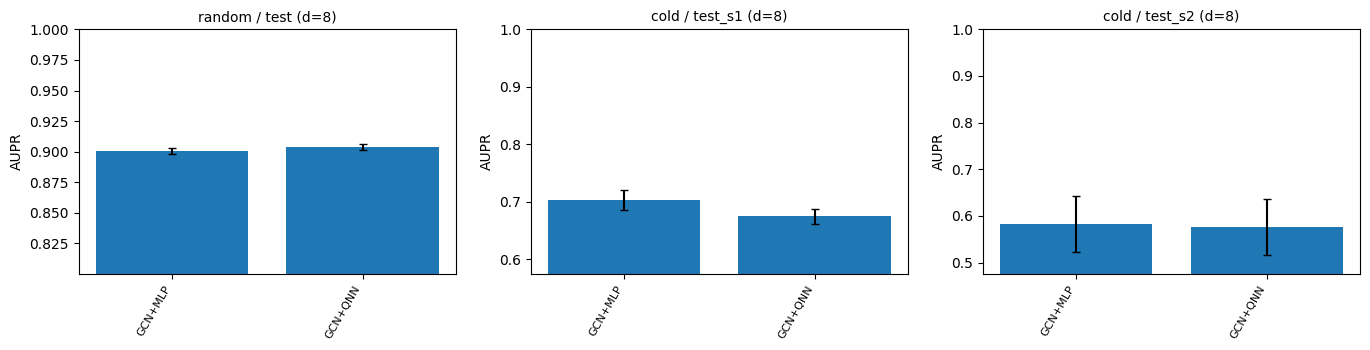

In [ ]:
import matplotlib.pyplot as plt
d0 = D_LIST[0]; sub = res[res.d == d0]
groups = sub[["regime", "test"]].drop_duplicates().values.tolist()
fig, axes = plt.subplots(1, len(groups), figsize=(4.6 * len(groups), 3.6), squeeze=False)
for ax, (rg, ts) in zip(axes[0], groups):
    g = sub[(sub.regime == rg) & (sub.test == ts)].groupby("model").AUPR.agg(["mean", "std"]).reindex(order)
    ax.bar(range(len(g)), g["mean"], yerr=g["std"].fillna(0), capsize=3)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{rg} / {ts} (d={d0})", fontsize=10); ax.set_ylabel("AUPR"); ax.set_ylim(max(0.4, g["mean"].min() - 0.1), 1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/aupr_bars.png", dpi=150); plt.show()

## 8. Paired comparison: QNN vs MLP
Per-seed difference ΔAUPR = AUPR(GCN+QNN) − AUPR(GCN+MLP), with a 95% t-confidence interval.
This is a **preliminary** comparison, not the full falsifier: the pre-registered test also needs the parameter-matched MLP and the no-entanglement circuit (planned next). Note the MLP decoder here has more parameters than the QNN.

In [ ]:
from scipy import stats
piv = res.pivot_table(index=["regime", "test", "d", "seed"], columns="model", values="AUPR")
out = []
for (rg, ts, d), g in piv.groupby(level=["regime", "test", "d"]):
    dlt = (g["GCN+QNN"] - g["GCN+MLP"]).dropna().values
    if len(dlt) >= 2:
        m, se = dlt.mean(), dlt.std(ddof=1) / np.sqrt(len(dlt)); h = stats.t.ppf(0.975, len(dlt) - 1) * se
        ci = f"[{m - h:.3f}, {m + h:.3f}]"; incl0 = (m - h) <= 0 <= (m + h)
    else:
        m, ci, incl0 = float("nan"), "n/a (need >= 2 seeds)", None
    out.append(dict(regime=rg, test=ts, d=d, n_seeds=len(dlt), dAUPR=round(m, 4), CI95=ci, CI_includes_zero=incl0))
cmp_ = pd.DataFrame(out); display(cmp_); cmp_.to_csv(f"{OUT_DIR}/qnn_vs_mlp.csv", index=False)
if len(SEEDS) < 5: print(f"NOTE: only {len(SEEDS)} seeds. Use 5 for the final numbers.")

,regime,test,d,n_seeds,dAUPR,CI95,CI_includes_zero
0,cold,test_s1,8,5,-0.0280,"[-0.042, -0.014]",False
1,cold,test_s2,8,5,-0.0067,"[-0.039, 0.026]",True
2,random,test,8,5,0.0035,"[0.002, 0.005]",False


## 9. Package the outputs (for the GitHub repo / report)

In [ ]:
import shutil
shutil.make_archive("week1_outputs", "zip", ".", OUT_DIR); print("wrote week1_outputs.zip (results tables + figure)")
try:
    from google.colab import files; files.download("week1_outputs.zip")
except Exception:
    pass

wrote week1_outputs.zip (results tables + figure)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>